# The entropy of a crystal from MD, checked against the exact answer

Hermes measures the entropy of a phase from a molecular-dynamics trajectory. This notebook takes fcc copper on
Mishin's EAM potential (Phys. Rev. B 63, 224106 (2001), https://doi.org/10.1103/PhysRevB.63.224106) and compares
Hermes's entropy with the exact value from thermodynamic integration on the same potential (calphy, Phys. Rev.
Materials 5, 103801 (2021), https://doi.org/10.1103/PhysRevMaterials.5.103801).

The data come from the last held-out test in
[docs/validation.md](https://github.com/odinzen/hermes/blob/main/docs/validation.md): 864 atoms, each box relaxed to
zero pressure at its temperature, then 200 ps at constant volume with a frame every 0.5 ps.

1. At 480 K, about a third of copper's melting point, Hermes reads the entropy straight from the atoms' motion.
2. At 1150 K, close to melting, the same reading comes out too high.
3. The heat-capacity route carries the 480 K value up to 1150 K with the enthalpy of a few short runs.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

from hermes.compression_entropy import (
    crystal_correlation_entropy,
    gaussian_entropy,
    trajectory_entropy,
)
from hermes.heat_capacity import entropy_from_heat_capacity
from hermes.md_configuration import CLASSICAL_ENTROPY_OFFSET

runs = {t: np.load(f"cu_mishin_{t}K.npz") for t in (480, 1150)}
exact = json.load(open("cu_mishin_exact_entropy.json"))
for t, run in runs.items():
    frames, atoms, _ = run["positions"].shape
    print(f"{t} K: {frames} frames of {atoms} atoms, "
          f"exact S = {exact[str(t)]:.2f} J/(K mol)")

480 K: 401 frames of 864 atoms, exact S = 44.44 J/(K mol)
1150 K: 401 frames of 864 atoms, exact S = 68.35 J/(K mol)


## 1. At 480 K: the entropy from the atoms' motion

Hermes treats each atom's motion and then takes away what the atoms share, because neighbours move together.
There are two ways to read each atom's own entropy:

- **Gaussian:** from the spread of each atom about its site.
- **Compression:** the number of bits it takes to write the atoms' positions down, after Fisher and Hong
  (arXiv:2512.02221). It needs no assumption about the shape of the motion.

The shared part is taken exactly from the crystal's repeating structure (`crystal_correlation_entropy`). It also
returns the entropy of the crystal's centre of mass, which the simulation holds still.

In [2]:
def direct_routes(t):
    run = runs[t]
    x, cell = run["positions"].astype(float), run["cell"]
    masses = np.full(x.shape[1], float(run["mass_amu"]))
    shared = crystal_correlation_entropy(x, cell)
    gauss = gaussian_entropy(x, cell, masses, t)
    comp = trajectory_entropy(x, cell, masses, t, n_pairs=60,
                              min_separation=10)
    compression = (comp["mean"] + CLASSICAL_ENTROPY_OFFSET
                   - shared["entropy"])
    return gauss, compression, shared


low = direct_routes(480)
gauss, compression, shared = low
print(f"shared by the atoms   {shared['shared']:6.2f} J/(K mol)")
print(f"centre of mass        {shared['centre_of_mass']:6.2f}")
print(f"Gaussian route        {gauss['entropy']:6.2f}")
print(f"compression route     {compression:6.2f}")
print(f"exact                 {exact['480']:6.2f}")

shared by the atoms     4.36 J/(K mol)
centre of mass          0.21
Gaussian route         44.90
compression route      44.85
exact                  44.44


Both routes land within half a J/(K mol) of the exact value, about 1 % of the entropy.

## 2. At 1150 K: close to melting the direct reading is too high

Near melting the atoms' motion is no longer Gaussian as a whole. Each atom on its own, and each pair of neighbours,
still looks Gaussian, but three or more atoms move together in ways a Gaussian picture cannot hold. The direct
routes then overestimate the entropy.

In [3]:
high = direct_routes(1150)
print(f"Gaussian route        {high[0]['entropy']:6.2f} J/(K mol)")
print(f"compression route     {high[1]:6.2f}")
print(f"exact                 {exact['1150']:6.2f}")

Gaussian route         69.70 J/(K mol)
compression route      69.48
exact                  68.35


## 3. The heat-capacity route: carry the moderate-temperature value up

Thermodynamics needs no picture of the motion. At constant pressure

$$S(T) = S(T_0) + \int_{T_0}^{T} \frac{C_P}{T'}\,dT',$$

and the heat capacity follows from the enthalpy H = U + K + PV of short constant-pressure runs at a few
temperatures. Hermes fits H(T) with a cubic and integrates exactly, starting from the Gaussian value at 480 K.

In [4]:
ladder = np.loadtxt("cu_mishin_enthalpy.csv", delimiter=",")
temps, pe, pv = ladder.T
k_ev, ev_to_j = 8.617333262e-5, 96485.33212
enthalpy = (pe + 1.5 * k_ev * temps + pv) * ev_to_j  # J/mol

route = entropy_from_heat_capacity(temps, enthalpy, 480.0,
                                   low[0]["entropy"], at=1150.0)
s_hc = route["entropy"][0]
print(f"enthalpy fit rms      {route['residual']:6.1f} J/mol")
print(f"heat-capacity route   {s_hc:6.2f} J/(K mol)")
print(f"exact                 {exact['1150']:6.2f}")

enthalpy fit rms         8.4 J/mol
heat-capacity route    68.71 J/(K mol)
exact                  68.35


The left panel shows the entropy over the whole range; the right one shows how far each reading lies from
the exact value at the two temperatures, which the left panel's scale hides.

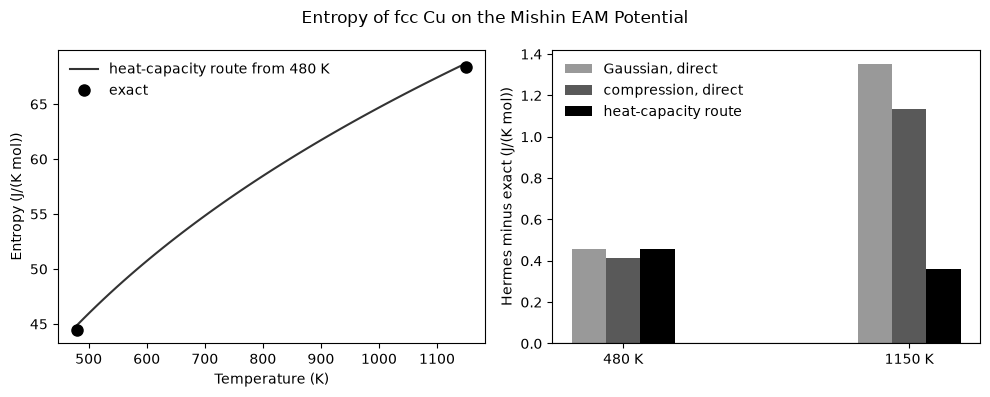

In [5]:
grid = np.linspace(480.0, 1150.0, 60)
curve = entropy_from_heat_capacity(temps, enthalpy, 480.0,
                                   low[0]["entropy"], at=grid)

fig, (left, right) = plt.subplots(1, 2, figsize=(10.0, 4.0))
left.plot(grid, curve["entropy"], color="0.2",
          label="heat-capacity route from 480 K")
left.plot([480, 1150], [exact["480"], exact["1150"]], "o",
          color="0.0", markersize=8, label="exact")
left.set_xlabel("Temperature (K)")
left.set_ylabel("Entropy (J/(K mol))")
left.legend(frameon=False)

readings = {
    "Gaussian, direct": (low[0]["entropy"], high[0]["entropy"]),
    "compression, direct": (low[1], high[1]),
    "heat-capacity route": (low[0]["entropy"], s_hc),
}
shades = ("0.6", "0.35", "0.0")
for (name, (s_low, s_high)), shade, dx in zip(readings.items(), shades,
                                              (-0.12, 0.0, 0.12)):
    errors = (s_low - exact["480"], s_high - exact["1150"])
    right.bar(np.array([0, 1]) + dx, errors, width=0.12, color=shade,
              label=name)
right.axhline(0.0, color="0.0", linewidth=0.8)
right.set_xticks([0, 1], ["480 K", "1150 K"])
right.set_ylabel("Hermes minus exact (J/(K mol))")
right.legend(frameon=False)
fig.suptitle("Entropy of fcc Cu on the Mishin EAM Potential")
fig.tight_layout()

The heat-capacity route lands within about half a J/(K mol) of the exact value at 1150 K, where the direct
reading is off by more than one. Its remaining error is the one it starts with at 480 K: the integration itself
adds almost nothing. That is the pattern across all nine metals of the held-out test in
[docs/validation.md](https://github.com/odinzen/hermes/blob/main/docs/validation.md).

## Next

- `hermes.formation.espei_formation_datasets` writes the enthalpy, entropy and heat capacity of a compound as
  ESPEI datasets, against the elements computed the same way; ESPEI fits a Gibbs function from them and pycalphad
  uses it.
- `hermes.quantum_correction` adds the quantum part these classical simulations leave out, from the vibrational
  spectrum of the same run.